# Lab Assignment 2 — AI in Healthcare (CSET343)
### Data Cleaning and Enrichment on the Heart Failure Clinical Records Dataset

This notebook performs data cleaning, enrichment, and preprocessing on the **Heart Failure Clinical Records Dataset**, following all 14 tasks of the lab assignment.

In [1]:
# ------------------------------------------------------------
# 0. Setup: import libraries
# ------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler, LabelEncoder

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

pd.set_option("display.max_columns", None)
np.random.seed(42)

## 1. Dataset Acquisition

Download the **Heart Failure Clinical Records Dataset** directly from a public raw GitHub mirror of the UCI/Kaggle dataset. If you already have the CSV locally, set `LOCAL_PATH` below instead.

In [2]:
# ------------------------------------------------------------
# 1. Dataset Acquisition
# ------------------------------------------------------------
DATA_URL = "https://raw.githubusercontent.com/dimikara/heart-failure-prediction/master/heart_failure_clinical_records_dataset.csv"
LOCAL_PATH =  "heart_failure_clinical_records_dataset.csv"

if LOCAL_PATH:
    df = pd.read_csv(LOCAL_PATH)
else:
    df = pd.read_csv(DATA_URL)

print("Dataset downloaded successfully.")
print("Shape:", df.shape)

Dataset downloaded successfully.
Shape: (299, 13)


## 2. Load Dataset

Read the dataset as a pandas DataFrame and display the first 5 rows.

In [3]:
# ------------------------------------------------------------
# 2. Load Dataset
# ------------------------------------------------------------
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


### (Synthetic step) Injecting missing values

The raw dataset has no missing values. To make Tasks 3–14 meaningful, we randomly blank out ~8% of values in a handful of numerical and categorical columns.

In [4]:
# ------------------------------------------------------------
# Synthetic: inject missing values (MCAR) for demonstration
# ------------------------------------------------------------
df_raw = df.copy()  # keep an untouched copy for reference

cols_to_blank = ["age", "ejection_fraction", "serum_creatinine", "platelets", "smoking", "sex"]
frac_missing = 0.08

rng = np.random.default_rng(42)
for col in cols_to_blank:
    n_missing = int(len(df) * frac_missing)
    idx = rng.choice(df.index, size=n_missing, replace=False)
    df.loc[idx, col] = np.nan

print("Missing values injected. Current missing count per column:")
print(df.isnull().sum())

Missing values injected. Current missing count per column:
age                         23
anaemia                      0
creatinine_phosphokinase     0
diabetes                     0
ejection_fraction           23
high_blood_pressure          0
platelets                   23
serum_creatinine            23
serum_sodium                 0
sex                         23
smoking                     23
time                         0
DEATH_EVENT                  0
dtype: int64


## 3. Summarize Dataset

Report the number of rows, columns, data types, and missing values.

In [5]:
# ------------------------------------------------------------
# 3. Summarize Dataset
# ------------------------------------------------------------
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

print("\nData types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nGeneral info:")
df.info()

print("\nSummary statistics (numerical columns):")
df.describe()

Number of rows: 299
Number of columns: 13

Data types:
age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction           float64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                         float64
smoking                     float64
time                          int64
DEATH_EVENT                   int64
dtype: object

Missing values per column:
age                         23
anaemia                      0
creatinine_phosphokinase     0
diabetes                     0
ejection_fraction           23
high_blood_pressure          0
platelets                   23
serum_creatinine            23
serum_sodium                 0
sex                         23
smoking                     23
time                         0
DEATH_EVENT                  0
dtype: int64

General info:
<cla

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
count,276.000000,299.000000,299.000000,299.000000,276.000000,299.000000,276.000000,276.000000,299.000000,276.000000,276.000000,299.000000,299.00000
mean,60.316428,0.431438,581.839465,0.418060,38.170290,0.351171,264720.567609,1.393514,136.625418,0.644928,0.318841,130.260870,0.32107
std,11.692306,0.496107,970.287881,0.494067,11.938783,0.478136,99080.477165,1.042210,4.412477,0.479405,0.466874,77.614208,0.46767
min,40.000000,0.000000,23.000000,0.000000,14.000000,0.000000,47000.000000,0.500000,113.000000,0.000000,0.000000,4.000000,0.00000
25%,50.000000,0.000000,116.500000,0.000000,30.000000,0.000000,210750.000000,0.900000,134.000000,0.000000,0.000000,73.000000,0.00000
50%,60.000000,0.000000,250.000000,0.000000,38.000000,0.000000,261000.000000,1.100000,137.000000,1.000000,0.000000,115.000000,0.00000
75%,68.250000,1.000000,582.000000,1.000000,45.000000,1.000000,305000.000000,1.400000,140.000000,1.000000,1.000000,203.000000,1.00000
max,95.000000,1.000000,7861.000000,1.000000,80.000000,1.000000,850000.000000,9.400000,148.000000,1.000000,1.000000,285.000000,1.00000


## 4. Visualize Missing Values

Heatmap of missing values using seaborn.

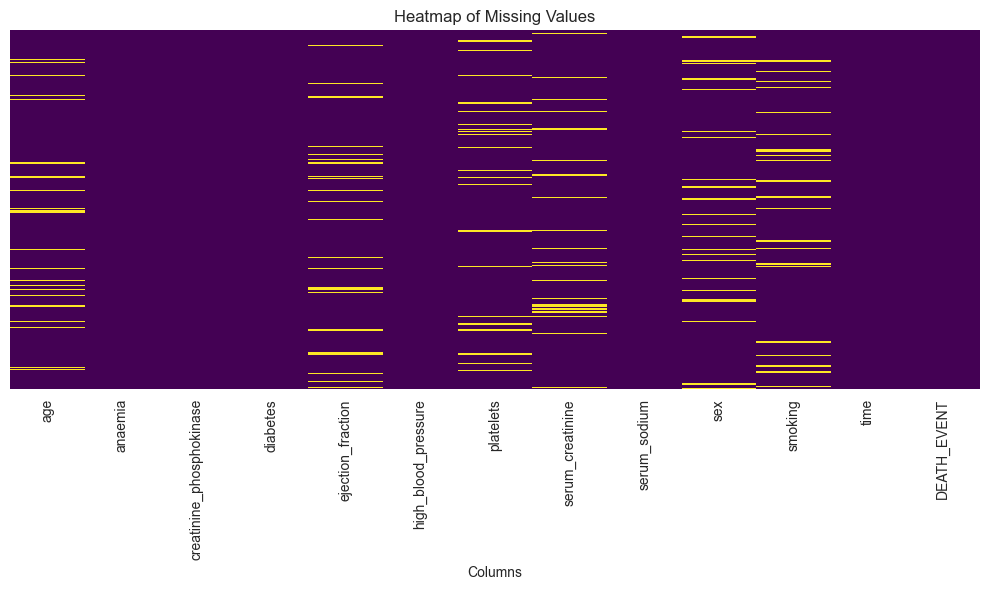

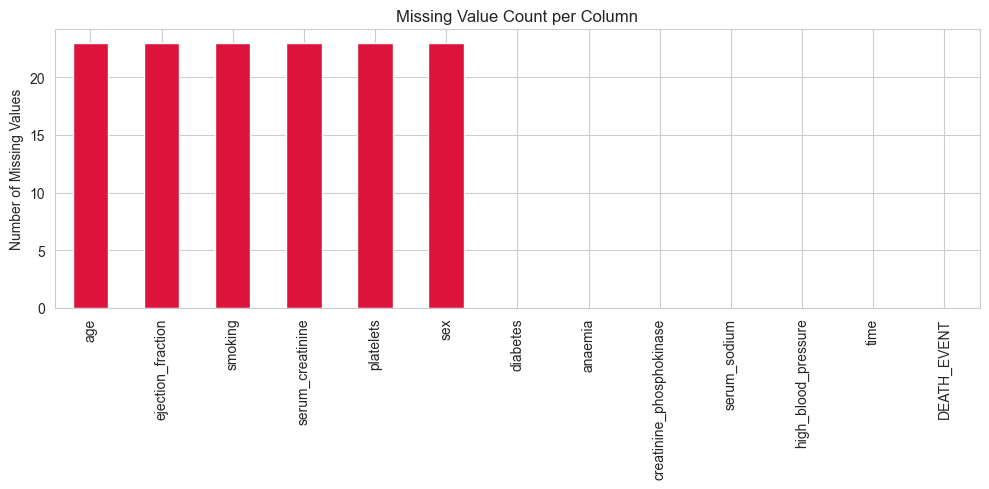

In [6]:
# ------------------------------------------------------------
# 4. Visualize Missing Values
# ------------------------------------------------------------
plt.figure(figsize=(10, 6))
sns.heatmap(df.isnull(), cbar=False, cmap="viridis", yticklabels=False)
plt.title("Heatmap of Missing Values")
plt.xlabel("Columns")
plt.tight_layout()
plt.show()

# Bar chart of missing value counts
plt.figure(figsize=(10, 5))
df.isnull().sum().sort_values(ascending=False).plot(kind="bar", color="crimson")
plt.title("Missing Value Count per Column")
plt.ylabel("Number of Missing Values")
plt.tight_layout()
plt.show()

## 5. Plot Distributions

Histograms and boxplots for key numerical features.

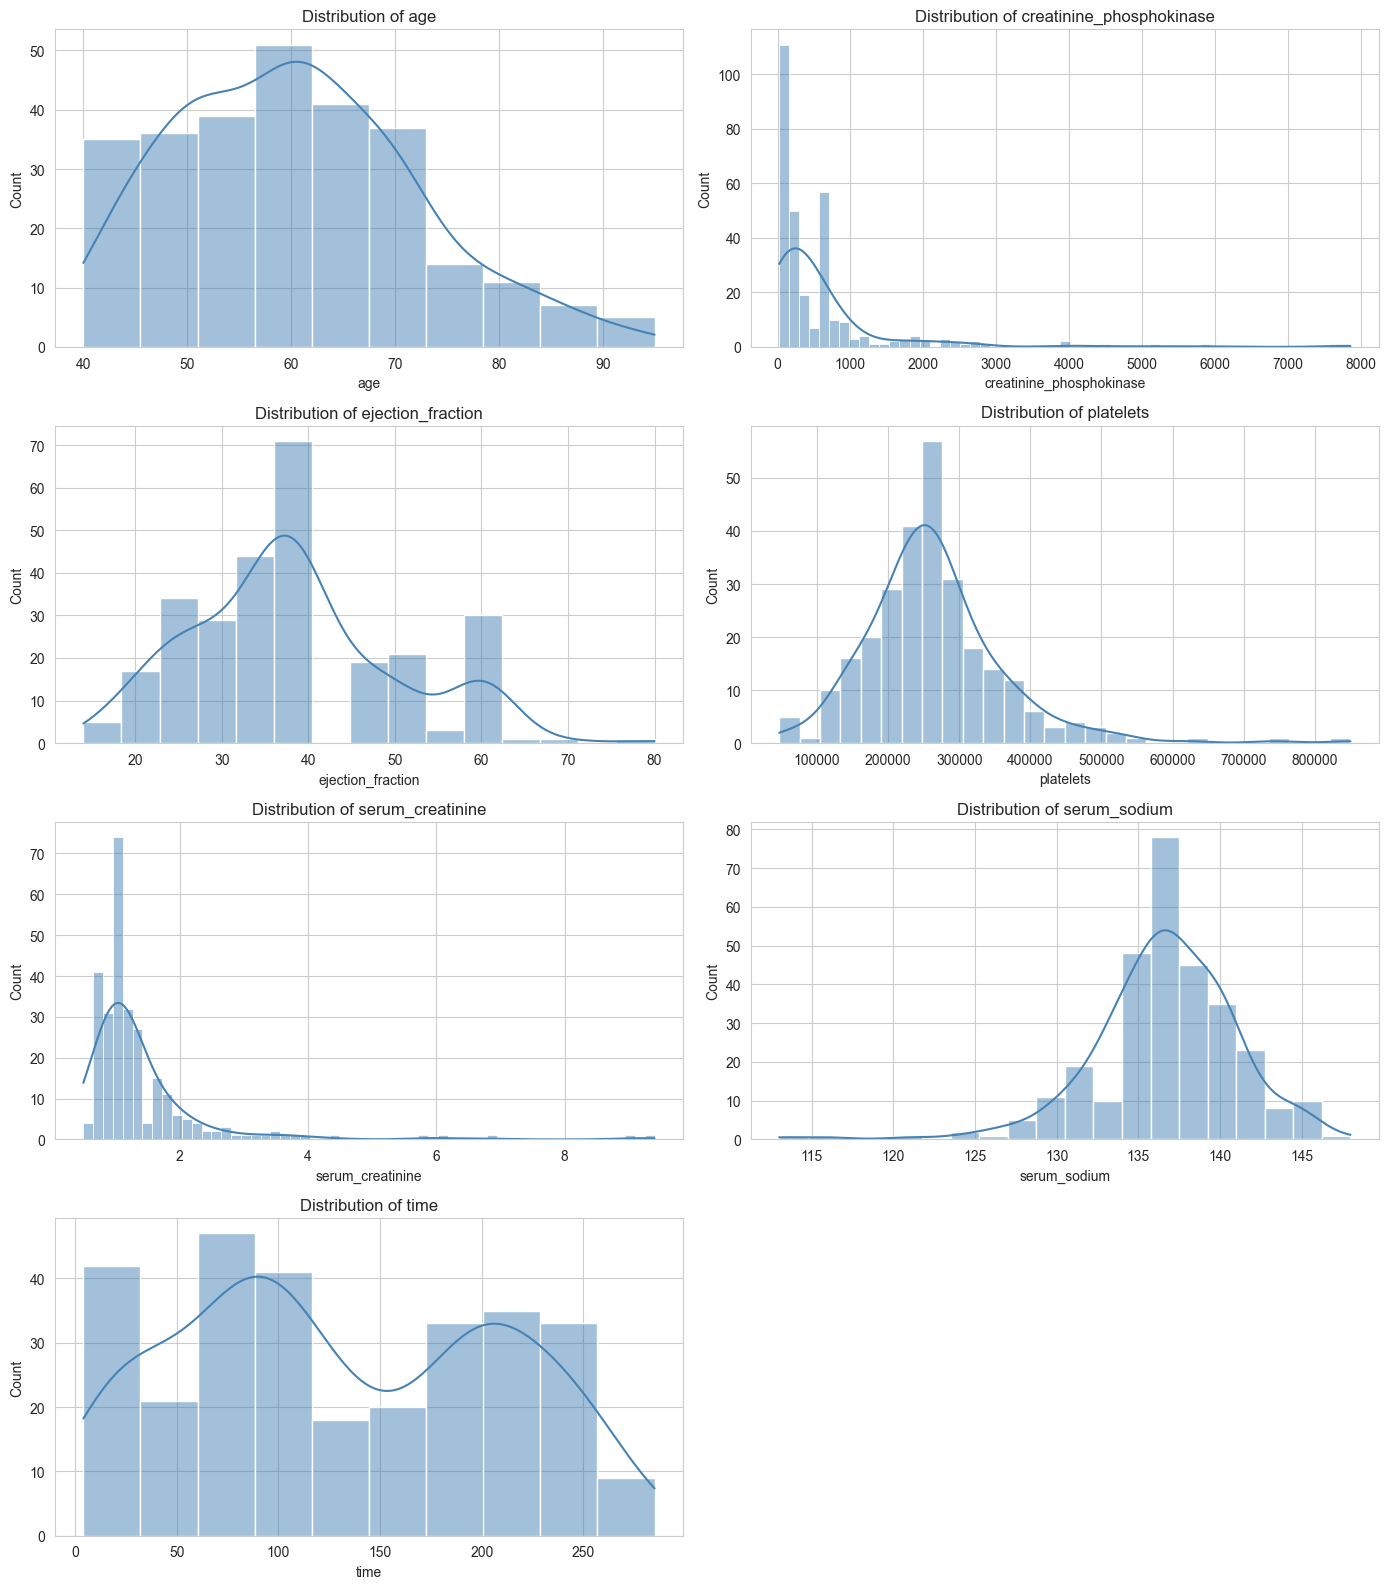

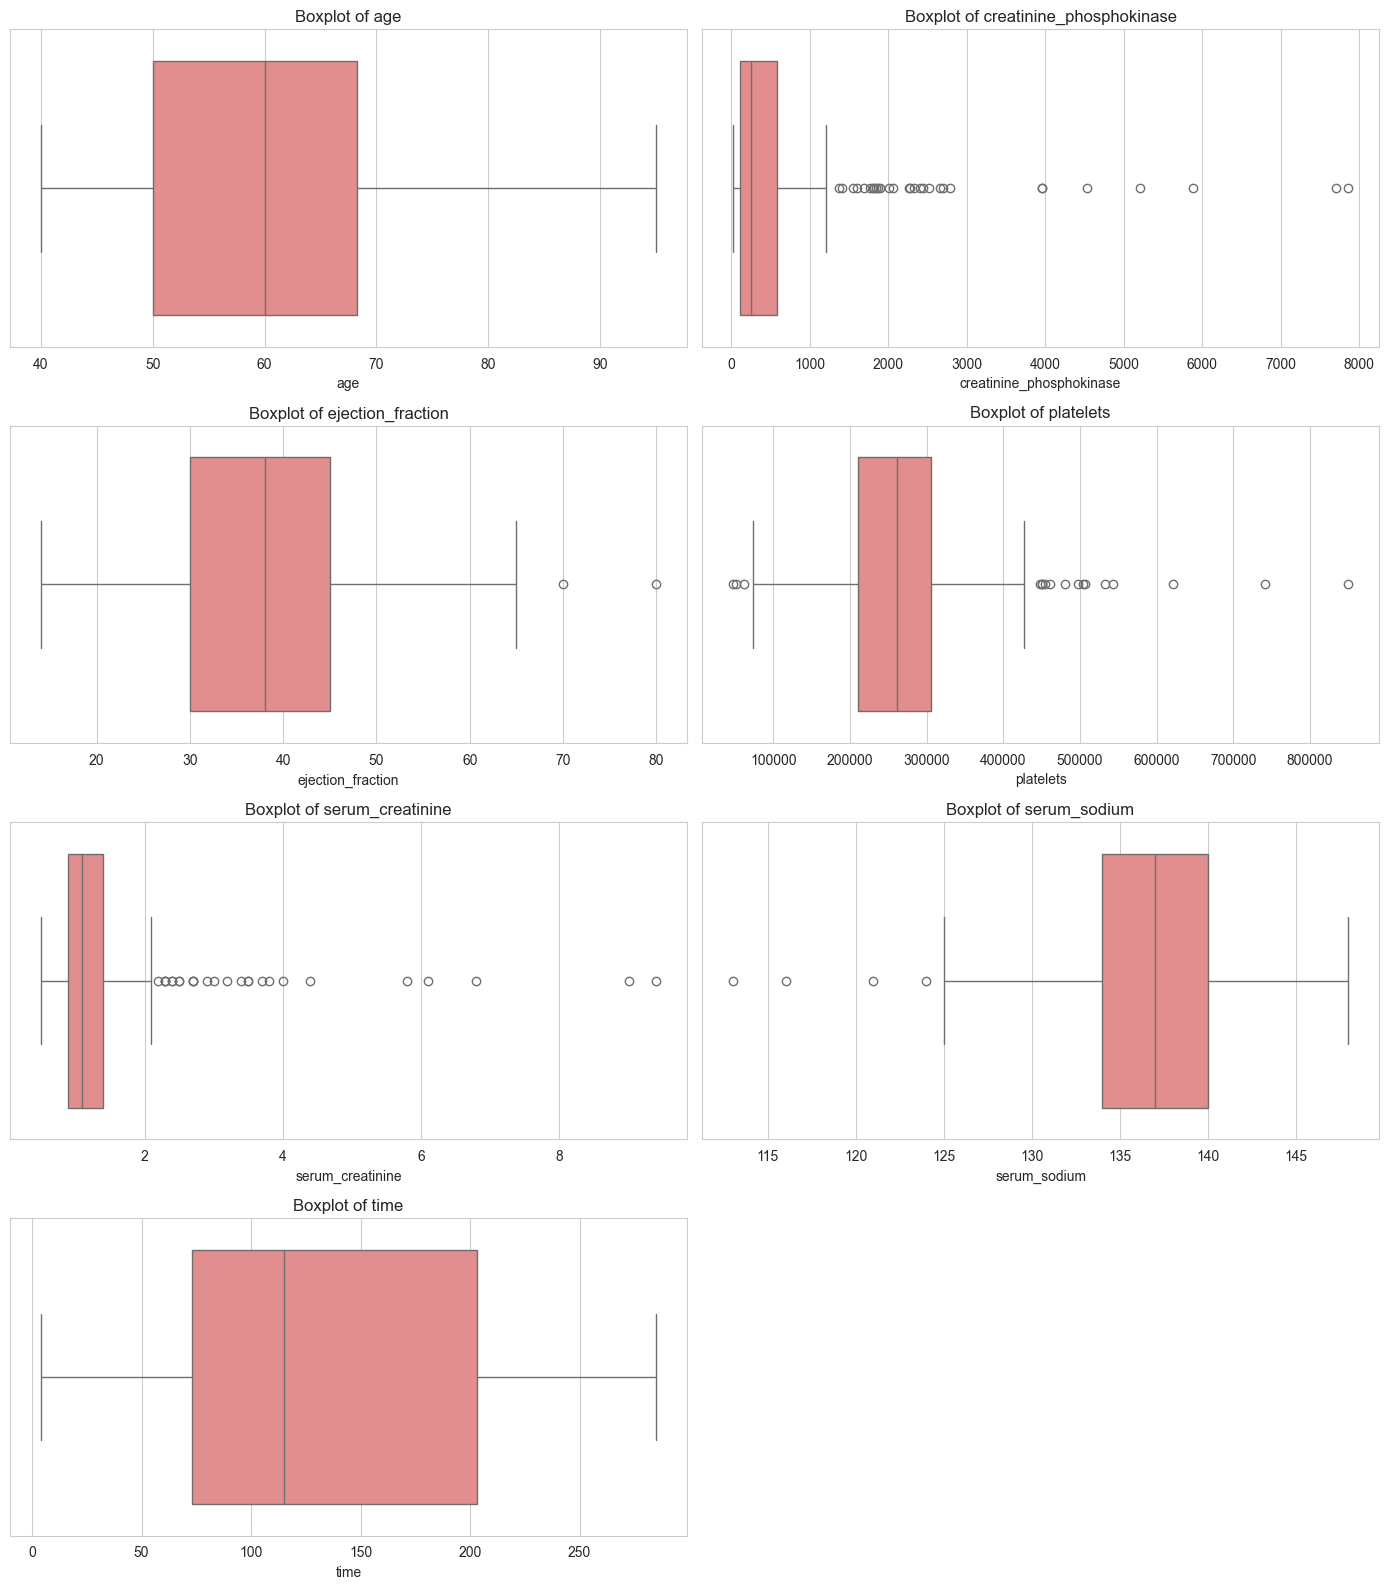

In [7]:
# ------------------------------------------------------------
# 5. Plot Distributions (before cleaning)
# ------------------------------------------------------------
numerical_features = ["age", "creatinine_phosphokinase", "ejection_fraction",
                       "platelets", "serum_creatinine", "serum_sodium", "time"]

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()
for i, col in enumerate(numerical_features):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color="steelblue")
    axes[i].set_title(f"Distribution of {col}")
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()
for i, col in enumerate(numerical_features):
    sns.boxplot(x=df[col].dropna(), ax=axes[i], color="lightcoral")
    axes[i].set_title(f"Boxplot of {col}")
fig.delaxes(axes[-1])
plt.tight_layout()
plt.show()

## 6. Impute Missing Values

- **Numerical features** (`age`, `ejection_fraction`, `serum_creatinine`, `platelets`): impute with the **median** (robust to outliers/skew).
- **Categorical features** (`smoking`, `sex`): impute with the **mode**.

In [8]:
# ------------------------------------------------------------
# 6. Impute Missing Values
# ------------------------------------------------------------
df_clean = df.copy()

numerical_to_impute = ["age", "ejection_fraction", "serum_creatinine", "platelets"]
categorical_to_impute = ["smoking", "sex"]

# Numerical -> median
for col in numerical_to_impute:
    median_val = df_clean[col].median()
    df_clean[col] = df_clean[col].fillna(median_val)
    print(f"Imputed '{col}' with median = {median_val:.2f}")

# Categorical -> mode
for col in categorical_to_impute:
    mode_val = df_clean[col].mode()[0]
    df_clean[col] = df_clean[col].fillna(mode_val)
    print(f"Imputed '{col}' with mode = {mode_val}")

print("\nRemaining missing values after imputation:")
print(df_clean.isnull().sum())

Imputed 'age' with median = 60.00
Imputed 'ejection_fraction' with median = 38.00
Imputed 'serum_creatinine' with median = 1.10
Imputed 'platelets' with median = 261000.00
Imputed 'smoking' with mode = 0.0
Imputed 'sex' with mode = 1.0

Remaining missing values after imputation:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64


## 7. Remove Outliers

Use the **IQR method** on key numerical columns to detect and remove outliers.

In [9]:
# ------------------------------------------------------------
# 7. Remove Outliers (IQR method)
# ------------------------------------------------------------
def remove_outliers_iqr(data, columns, factor=1.5):
    data = data.copy()
    mask = pd.Series(True, index=data.index)
    for col in columns:
        Q1 = data[col].quantile(0.25)
        Q3 = data[col].quantile(0.75)
        IQR = Q3 - Q1
        lower = Q1 - factor * IQR
        upper = Q3 + factor * IQR
        col_mask = data[col].between(lower, upper)
        removed = (~col_mask).sum()
        print(f"{col}: removing {removed} outliers (bounds: {lower:.2f} to {upper:.2f})")
        mask &= col_mask
    return data[mask]

outlier_cols = ["creatinine_phosphokinase", "ejection_fraction", "platelets",
                 "serum_creatinine", "serum_sodium"]

rows_before = df_clean.shape[0]
df_clean = remove_outliers_iqr(df_clean, outlier_cols)
rows_after = df_clean.shape[0]

print(f"\nRows before outlier removal: {rows_before}")
print(f"Rows after outlier removal: {rows_after}")
print(f"Rows removed: {rows_before - rows_after}")

df_clean = df_clean.reset_index(drop=True)

creatinine_phosphokinase: removing 29 outliers (bounds: -581.75 to 1280.25)
ejection_fraction: removing 2 outliers (bounds: 7.50 to 67.50)
platelets: removing 20 outliers (bounds: 87750.00 to 429750.00)
serum_creatinine: removing 31 outliers (bounds: 0.22 to 2.03)
serum_sodium: removing 4 outliers (bounds: 125.00 to 149.00)

Rows before outlier removal: 299
Rows after outlier removal: 225
Rows removed: 74


## 8. Correct Inconsistencies

Check for and fix invalid entries — e.g. negative or biologically implausible values (negative age, negative ejection fraction, negative platelets/serum values, invalid binary flags).

In [10]:
# ------------------------------------------------------------
# 8. Correct Inconsistencies
# ------------------------------------------------------------
# Check for negative values in columns that must be non-negative
positive_cols = ["age", "creatinine_phosphokinase", "ejection_fraction",
                  "platelets", "serum_creatinine", "serum_sodium", "time"]

for col in positive_cols:
    n_negative = (df_clean[col] < 0).sum()
    if n_negative > 0:
        print(f"Found {n_negative} negative values in '{col}' -> correcting with abs()")
        df_clean[col] = df_clean[col].abs()
    else:
        print(f"'{col}': no negative values found.")

# Check binary/flag columns only contain {0, 1}
binary_cols = ["anaemia", "diabetes", "high_blood_pressure", "sex", "smoking", "DEATH_EVENT"]
for col in binary_cols:
    invalid = df_clean[~df_clean[col].isin([0, 1])]
    if len(invalid) > 0:
        print(f"'{col}': found {len(invalid)} invalid (non-binary) entries -> dropping them")
        df_clean = df_clean[df_clean[col].isin([0, 1])]
    else:
        print(f"'{col}': all values valid (0/1).")

# Sanity check: ejection_fraction should realistically be between 0 and 100 (%)
invalid_ef = df_clean[(df_clean["ejection_fraction"] < 0) | (df_clean["ejection_fraction"] > 100)]
print(f"\nInvalid ejection_fraction entries (outside 0-100%): {len(invalid_ef)}")
df_clean = df_clean[(df_clean["ejection_fraction"] >= 0) & (df_clean["ejection_fraction"] <= 100)]

df_clean = df_clean.reset_index(drop=True)
print(f"\nShape after correcting inconsistencies: {df_clean.shape}")

'age': no negative values found.
'creatinine_phosphokinase': no negative values found.
'ejection_fraction': no negative values found.
'platelets': no negative values found.
'serum_creatinine': no negative values found.
'serum_sodium': no negative values found.
'time': no negative values found.
'anaemia': all values valid (0/1).
'diabetes': all values valid (0/1).
'high_blood_pressure': all values valid (0/1).
'sex': all values valid (0/1).
'smoking': all values valid (0/1).
'DEATH_EVENT': all values valid (0/1).

Invalid ejection_fraction entries (outside 0-100%): 0

Shape after correcting inconsistencies: (225, 13)


## 9. Feature Engineering

- `age_group`: bins the patient's age into `<40`, `40-60`, `>60`.
- `risk_score`: a normalized composite score derived from `ejection_fraction` and `serum_creatinine` (higher serum creatinine and lower ejection fraction indicate higher risk).

In [11]:
# ------------------------------------------------------------
# 9. Feature Engineering
# ------------------------------------------------------------
# age_group
bins = [0, 40, 60, np.inf]
labels = ["<40", "40-60", ">60"]
df_clean["age_group"] = pd.cut(df_clean["age"], bins=bins, labels=labels, right=True)

print(df_clean["age_group"].value_counts())

# risk_score: normalize ejection_fraction (inverted, since lower EF = higher risk)
# and serum_creatinine (higher = higher risk), then combine.
ef_norm = 1 - (df_clean["ejection_fraction"] - df_clean["ejection_fraction"].min()) / \
              (df_clean["ejection_fraction"].max() - df_clean["ejection_fraction"].min())

sc_norm = (df_clean["serum_creatinine"] - df_clean["serum_creatinine"].min()) / \
          (df_clean["serum_creatinine"].max() - df_clean["serum_creatinine"].min())

df_clean["risk_score"] = (ef_norm * sc_norm).round(4)

df_clean[["age", "age_group", "ejection_fraction", "serum_creatinine", "risk_score"]].head(10)

age_group
40-60    123
>60       96
<40        6
Name: count, dtype: int64


,age,age_group,ejection_fraction,serum_creatinine,risk_score
0,75.0,>60,20.0,1.9,0.8824
1,65.0,>60,20.0,1.1,0.3394
2,50.0,40-60,20.0,1.9,0.8824
3,75.0,>60,15.0,1.2,0.4525
4,65.0,>60,65.0,1.5,0.0000
5,62.0,>60,25.0,0.9,0.1810
6,45.0,40-60,38.0,1.1,0.2036
7,50.0,40-60,38.0,1.1,0.2036
8,49.0,40-60,30.0,1.0,0.2112
9,87.0,>60,38.0,0.9,0.1222


## 10. Encode Categorical Variables

- `sex` and `smoking` are already binary (0/1) in the source data, but we demonstrate both **label encoding** (in place, for already-binary columns) and **one-hot encoding** for `age_group`, a genuinely multi-category feature.

In [12]:
# ------------------------------------------------------------
# 10. Encode Categorical Variables
# ------------------------------------------------------------
df_encoded = df_clean.copy()

# Label encoding example (sex, smoking are already 0/1, so this is a no-op safeguard
# in case they were loaded as strings/objects)
for col in ["sex", "smoking"]:
    if df_encoded[col].dtype == object:
        le = LabelEncoder()
        df_encoded[col] = le.fit_transform(df_encoded[col])
        print(f"Label-encoded '{col}': {dict(zip(le.classes_, le.transform(le.classes_)))}")
    else:
        print(f"'{col}' already numeric (0/1) -> no label encoding needed")

# One-hot encoding for age_group (genuinely categorical, >2 categories)
df_encoded = pd.get_dummies(df_encoded, columns=["age_group"], prefix="age_group")

df_encoded.head()

'sex' already numeric (0/1) -> no label encoding needed
'smoking' already numeric (0/1) -> no label encoding needed


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT,risk_score,age_group_<40,age_group_40-60,age_group_>60
0,75.0,0,582,0,20.0,1,265000.0,1.9,130,1.0,0.0,4,1,0.8824,False,False,True
1,65.0,0,146,0,20.0,0,162000.0,1.1,129,1.0,1.0,7,1,0.3394,False,False,True
2,50.0,1,111,0,20.0,0,210000.0,1.9,137,1.0,0.0,7,1,0.8824,False,True,False
3,75.0,1,246,0,15.0,0,127000.0,1.2,137,1.0,0.0,10,1,0.4525,False,False,True
4,65.0,0,157,0,65.0,0,261000.0,1.5,138,0.0,0.0,10,1,0.0000,False,False,True


## 11. Normalize Features

Scale numerical features to the 0–1 range using `MinMaxScaler`.

In [13]:
# ------------------------------------------------------------
# 11. Normalize Features
# ------------------------------------------------------------
df_normalized = df_encoded.copy()

cols_to_scale = ["age", "creatinine_phosphokinase", "ejection_fraction", "platelets",
                  "serum_creatinine", "serum_sodium", "time", "risk_score"]

scaler = MinMaxScaler()
df_normalized[cols_to_scale] = scaler.fit_transform(df_normalized[cols_to_scale])

df_normalized[cols_to_scale].head()

,age,creatinine_phosphokinase,ejection_fraction,platelets,serum_creatinine,serum_sodium,time,risk_score
0,0.648148,0.470990,0.117647,0.468852,1.000000,0.217391,0.000000,1.000000
1,0.462963,0.098976,0.117647,0.131148,0.384615,0.173913,0.010676,0.384633
2,0.185185,0.069113,0.117647,0.288525,1.000000,0.521739,0.010676,1.000000
3,0.648148,0.184300,0.019608,0.016393,0.461538,0.521739,0.021352,0.512806
4,0.462963,0.108362,1.000000,0.455738,0.692308,0.565217,0.021352,0.000000


## 12. Compute Summary Statistics

Compare mean, median, and standard deviation **before** (raw data with injected missing values) and **after** cleaning/normalization.

In [14]:
# ------------------------------------------------------------
# 12. Compute Summary Statistics (Before vs After)
# ------------------------------------------------------------
compare_cols = ["age", "ejection_fraction", "serum_creatinine", "platelets"]

before_stats = df[compare_cols].agg(["mean", "median", "std"]).T
before_stats.columns = [f"{c}_before" for c in before_stats.columns]

after_stats = df_clean[compare_cols].agg(["mean", "median", "std"]).T
after_stats.columns = [f"{c}_after_cleaning" for c in after_stats.columns]

comparison = pd.concat([before_stats, after_stats], axis=1)
comparison

,mean_before,median_before,std_before,mean_after_cleaning,median_after_cleaning,std_after_cleaning
age,60.316428,60.0,11.692306,60.010373,60.0,10.956869
ejection_fraction,38.170290,38.0,11.938783,38.137778,38.0,11.248557
serum_creatinine,1.393514,1.1,1.042210,1.116178,1.1,0.297252
platelets,264720.567609,261000.0,99080.477165,256138.162267,261000.0,66100.103175


## 13. Validate Cleaning

Re-plot histograms/boxplots for the cleaned numerical features to visually confirm the cleaning worked (no extreme outliers, more regular distributions).

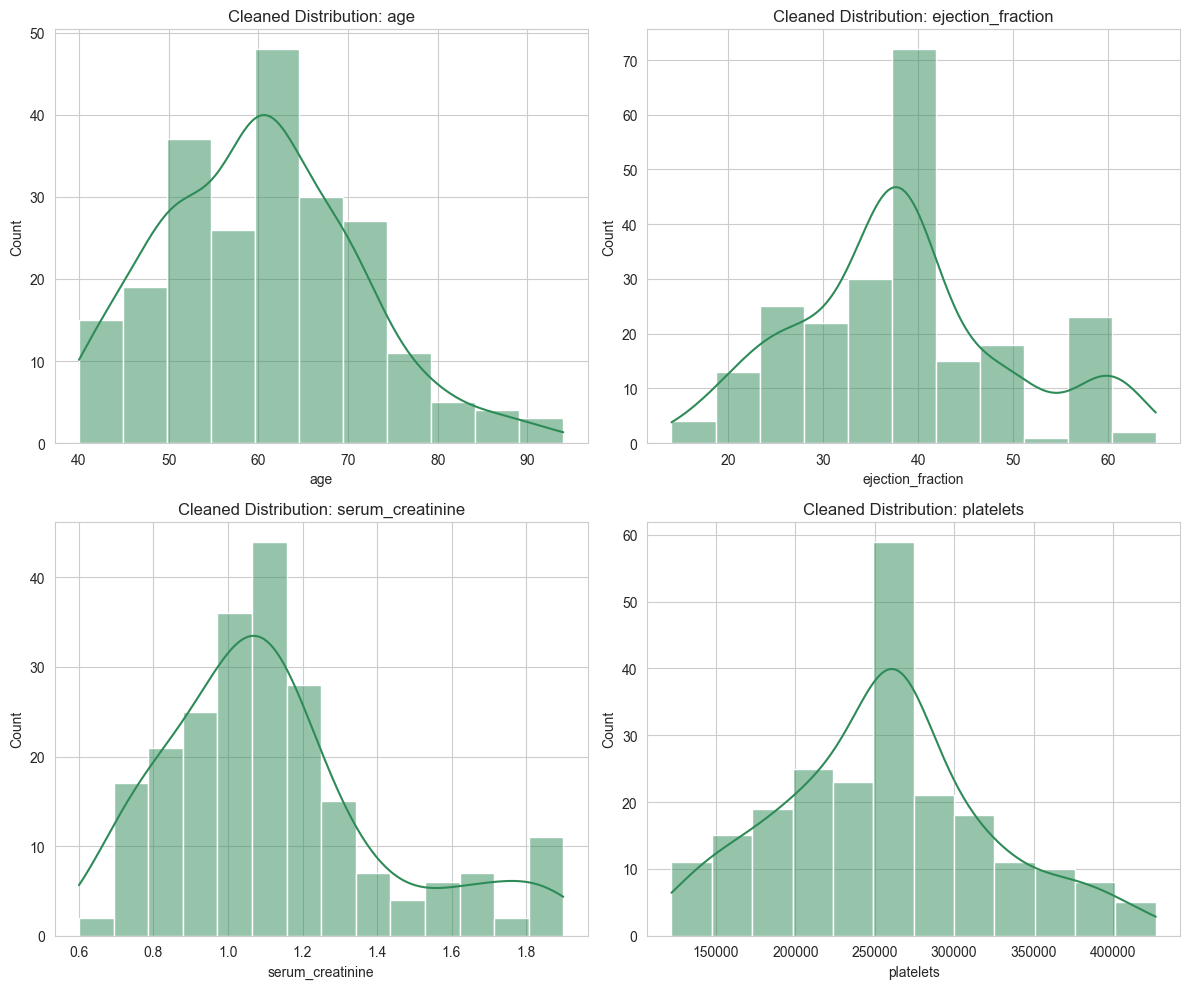

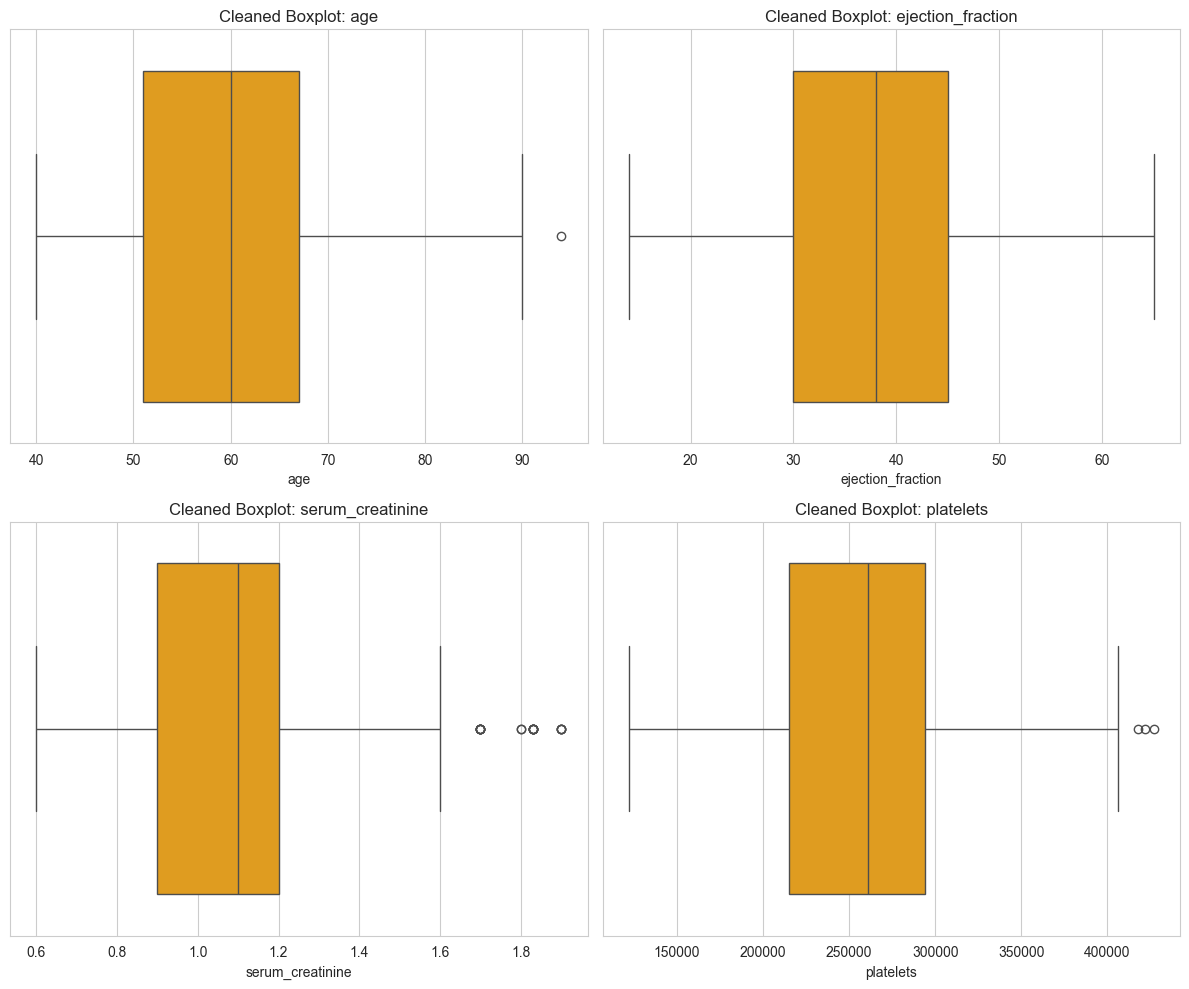

In [15]:
# ------------------------------------------------------------
# 13. Validate Cleaning
# ------------------------------------------------------------
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for i, col in enumerate(compare_cols):
    sns.histplot(df_clean[col], kde=True, ax=axes[i], color="seagreen")
    axes[i].set_title(f"Cleaned Distribution: {col}")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
for i, col in enumerate(compare_cols):
    sns.boxplot(x=df_clean[col], ax=axes[i], color="orange")
    axes[i].set_title(f"Cleaned Boxplot: {col}")
plt.tight_layout()
plt.show()

## 14. Check Missing Values

Confirm no missing values remain in the cleaned dataset.

In [16]:
# ------------------------------------------------------------
# 14. Check Missing Values (final confirmation)
# ------------------------------------------------------------
final_missing = df_clean.isnull().sum()
print("Missing values in final cleaned dataset:")
print(final_missing)

if final_missing.sum() == 0:
    print("\nNo missing values remain. Dataset is fully cleaned.")
else:
    print("\nSome missing values remain — see justification below.")
    print(final_missing[final_missing > 0])

Missing values in final cleaned dataset:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
age_group                   0
risk_score                  0
dtype: int64

No missing values remain. Dataset is fully cleaned.


## Conclusion

The dataset was acquired, summarized, and its missing values were visualized and imputed (median for numerical, mode for categorical). Outliers were removed using the IQR method, inconsistent/invalid entries were corrected, and two new features (`age_group`, `risk_score`) were engineered. Categorical variables were encoded, numerical features were normalized to [0, 1], and summary statistics before/after cleaning were compared. The final dataset was validated with distribution plots and confirmed to have no remaining missing values, making it ready for downstream modeling (e.g., predicting `DEATH_EVENT`).